In [1]:
import json
import matplotlib.pyplot as plt
import glob
import pandas as pd
import os
from matplotlib.colors import LogNorm
import matplotlib.cm as cm
import numpy as np
from pathlib import Path

In [11]:
def process_json(json_files):
    all_worker_data = []

    for file_path in json_files:
        file_name = os.path.basename(file_path)
        try:
            with open(file_path, "r") as f:
                data = json.load(f)

            # Look inside the "stats_per_job" nested dictionary
            if "stats_per_job" in data:
                jobs_dict = data["stats_per_job"]

                # Loop through each worker job (e.g., worker_job_62, worker_job_41)
                for job_id, job_stats in jobs_dict.items():
                    if "total_bytes_read" in job_stats:
                        all_worker_data.append(
                            {
                                "file_name": file_name,
                                "job_id": job_id,
                                "total_bytes_read": job_stats["total_bytes_read"],
                                "total_read_time_seconds": job_stats.get("total_read_time_seconds", None),
                                "read_requests": job_stats.get("read_requests", None),
                            }
                        )
        except Exception as e:
            print(f"Error reading {file_name}: {e}")

    # Convert our list of worker data into a DataFrame table
    worker_df = pd.DataFrame(all_worker_data)
    print(
        f"Successfully compiled {len(worker_df)} individual worker jobs across all JSON files."
    )
    return worker_df

In [25]:
def plot_size_vs_time(worker_df, label): 
    X_AXIS_COLUMN = "total_read_time_seconds"
    Y_AXIS_COLUMN = "total_bytes_read"

    filtered_worker_df = worker_df[
            (worker_df["total_bytes_read"] > 0)
            & (worker_df["total_read_time_seconds"] > 0)
        ]
    print(
            f"original={len(worker_df)}, "
            f"filtered={len(filtered_worker_df)}"
        )
    xbins = np.geomspace(
        max(1e-3, filtered_worker_df[X_AXIS_COLUMN].min()),   # geomspace can't start at 0
        filtered_worker_df[X_AXIS_COLUMN].max(),
        100,
    )

    ybins = np.geomspace(
        1000,                    # start at 10^0
        filtered_worker_df[Y_AXIS_COLUMN].max(),
        100,
    )


    fig, ax = plt.subplots(figsize=(8, 6))

    min_bytes_threshold = 0
    min_time_threshold = 0
    filtered_worker_df = worker_df[
        (worker_df["total_bytes_read"] > min_bytes_threshold) & (worker_df["total_read_time_seconds"] > min_time_threshold)
    ]
    # --- CREATE THE 2D FREQUENCY GRID ---
    # 'bins' controls how many range blocks grid the plot (e.g., 10x10 squares)
    # 'cmap' controls the color shading theme (e.g., 'Blues', 'viridis', 'Purples')
    counts, xedges, yedges, im = ax.hist2d(
        filtered_worker_df[X_AXIS_COLUMN],
        filtered_worker_df[Y_AXIS_COLUMN],
        bins=(xbins, ybins),
        cmap=cm.Blues,
        cmin=1, # This hides empty bins (makes them white instead of dark blue)
        norm=LogNorm()
        
    )

    # Add a color bar on the right side to show what the shading intensities mean
    cbar = plt.colorbar(im, ax=ax)
    cbar.set_label("Counts", fontsize=11)
    ax.set_title(f"Total Bytes Read vs Transfer Time, {label}", fontsize=14, fontweight='bold')
    ax.set_xlabel("Transfer Time (seconds)", fontsize=12)
    ax.set_ylabel("Total Bytes Read", fontsize=12)
    ax.grid(True, linestyle=":", alpha=0.4)
    ax.set_xscale('log')
    ax.set_yscale('log')
    ax.set_ylim(1000,1e12)
    ax.set_xlim(1e-3, 1e6)  # Set x-axis limits to avoid extreme outliers


    plt.tight_layout()
    plt.show()


In [27]:
json_file_path = "/uscms/home/jroderic/nobackup/diskproject/git_repo/dCache-billing-study/dune_json_files/Dune_Tammy/ReplayFiles/fd_hd_anu/2026*/*.json"
json_files = sorted(glob.glob(json_file_path))
n_files = len(json_files)
print(f"Number of JSON files: {n_files}")


Number of JSON files: 4601


In [28]:
worker_df = process_json(json_files)

Successfully compiled 230050 individual worker jobs across all JSON files.


original=230050, filtered=1338


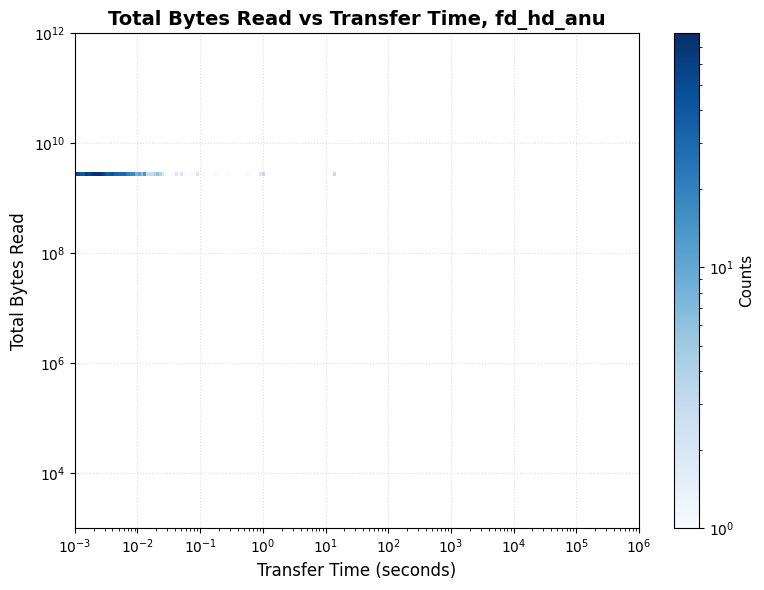

In [29]:
plot_size_vs_time(worker_df, label="fd_hd_anu")

Number of JSON files: 4252
Successfully compiled 175534 individual worker jobs across all JSON files.
original=175534, filtered=148112


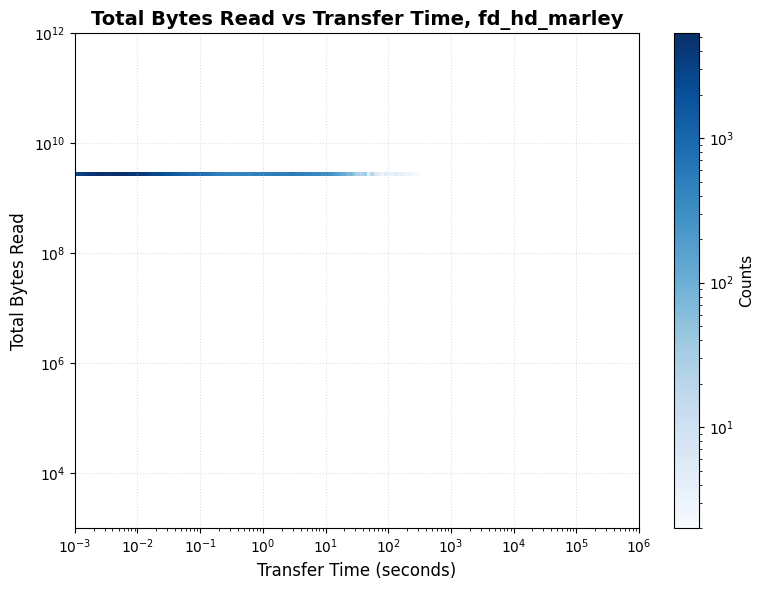

In [30]:
json_file_path = "/uscms/home/jroderic/nobackup/diskproject/git_repo/dCache-billing-study/dune_json_files/Dune_Tammy/ReplayFiles/fd_hd_marley/2026*/*.json"
json_files = sorted(glob.glob(json_file_path))
n_files = len(json_files)
print(f"Number of JSON files: {n_files}")
worker_df = process_json(json_files)
plot_size_vs_time(worker_df=worker_df, label="fd_hd_marley")

Number of JSON files: 5497
Successfully compiled 274604 individual worker jobs across all JSON files.
original=274604, filtered=76356


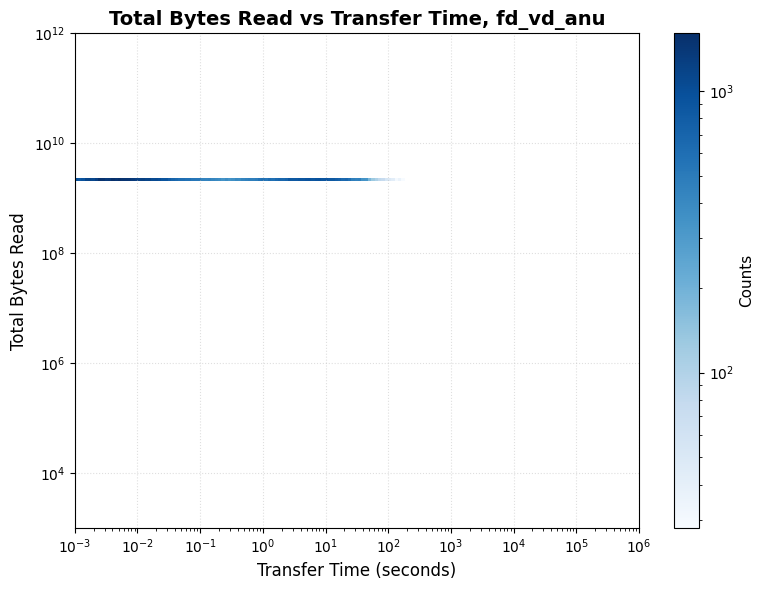

In [31]:
json_file_path = "/uscms/home/jroderic/nobackup/diskproject/git_repo/dCache-billing-study/dune_json_files/Dune_Tammy/ReplayFiles/fd_vd_anu/2026*/*.json"
json_files = sorted(glob.glob(json_file_path))
n_files = len(json_files)
print(f"Number of JSON files: {n_files}")
worker_df = process_json(json_files)
plot_size_vs_time(worker_df=worker_df, label="fd_vd_anu")

Number of JSON files: 4853
Successfully compiled 237799 individual worker jobs across all JSON files.
original=237799, filtered=64179


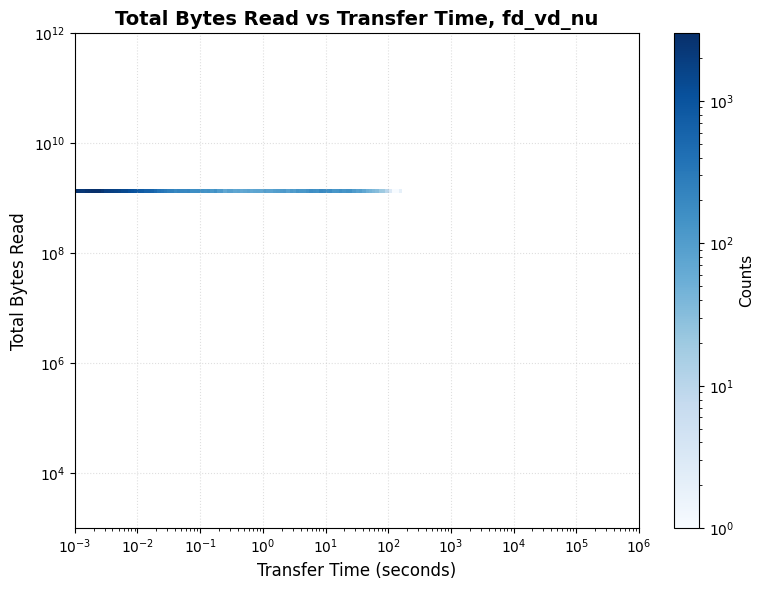

In [32]:
json_file_path = "/uscms/home/jroderic/nobackup/diskproject/git_repo/dCache-billing-study/dune_json_files/Dune_Tammy/ReplayFiles/fd_vd_nu/2026*/*.json"
json_files = sorted(glob.glob(json_file_path))
n_files = len(json_files)
print(f"Number of JSON files: {n_files}")
worker_df = process_json(json_files)
plot_size_vs_time(worker_df=worker_df, label="fd_vd_nu")

Number of JSON files: 117
Successfully compiled 5850 individual worker jobs across all JSON files.
original=5850, filtered=0


ValueError: x and y arguments to pcolormesh cannot have non-finite values or be of type numpy.ma.core.MaskedArray with masked values

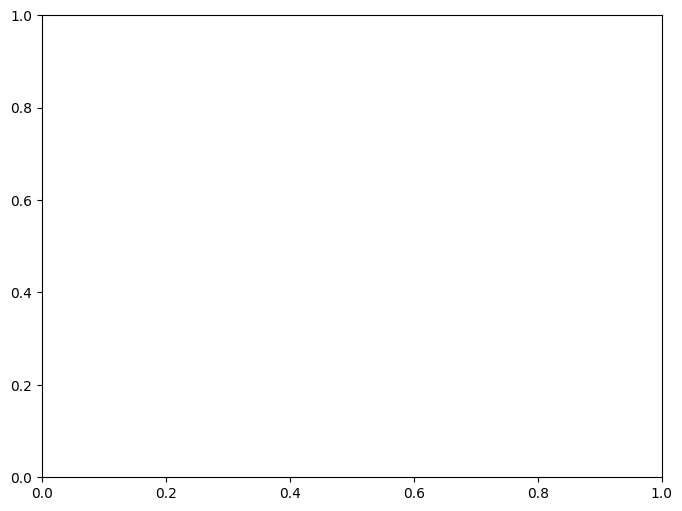

In [24]:
json_file_path = "/uscms/home/jroderic/nobackup/diskproject/git_repo/dCache-billing-study/dune_json_files/Dune_Tammy/ReplayFiles/ndlar_2x2/2026*/*.json"
json_files = sorted(glob.glob(json_file_path))
n_files = len(json_files)
print(f"Number of JSON files: {n_files}")
worker_df = process_json(json_files)
plot_size_vs_time(worker_df=worker_df)